In [1]:
# Python workflow to organize the Dust Deposition Database (D3) version 1

# Author: Samuel Albani

# History:
# First created: 13/04/2021
#  ...

In [2]:
# Import a few libraries

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from tqdm import tqdm
import csv
import more_itertools
from scipy import interpolate
    
from matplotlib.collections import PatchCollection
from matplotlib.patches import Rectangle
import matplotlib.gridspec as gridspec
import seaborn as sns

#import xarray as xr
import cartopy.crs as crs
import cartopy.feature as cfeature

In [3]:
# Define a few constants (and their relative uncertainties where appropriate)

# Decay constant of 230Th
marine_lambda230 = 0.009170554
marine_lambda230_RE = 0.11/75.584 # assumed to be the same as RE of Half-life of 230Th (ka)

# Production rate of Th230 from U234 [dpm/m3/a] from Kienast et al. 2016
marine_beta230 = 0.0255529
marine_beta230_RE = 0.0005 / marine_beta230

# Activity of Th230 per gram [dpm/g] from Kienast et al. 2016
ATh230tomass = 246186
ATh230tomass_RE = 0.

# Th232 in dust (ppb)
Th232todust = 13 * 1e-6
Th232todust_RE = 3 / 10.7 #(Th232todust/1e-6)

# ...


# ...


In [4]:
# Define a few short names for identifying columns

# GENERAL

Atop = 'Age top [ka B.P.]'
AtopRE = 'Age top R.E. [frac., 2σ]'
Abot = 'Age bottom [ka B.P.]'
AbotRE = 'Age bottom R.E. [frac., 2σ]'
Ac = 'Age center [ka B.P.]'
AcRE= 'Age center R.E. [frac., 2σ]'

Dtop = 'Depth top [m]'
Dbot = 'Depth bottom [m]'
Dc = 'Depth center [m]'


# MARINE SEDIMENTS

Th230 = 'ATh230 [dpm/g]'
Th230re = 'ATh230 R.E. [frac., 2σ]'
Th232 = 'ATh232 [dpm/g]'
Th232re = 'ATh232 R.E. [frac., 2σ]'
U234 = 'AU234 [dpm/g]'               # in fact, A234U is not used for calculations!
U234re = 'AU234 R.E. [frac., 2σ]'    # in fact, A234U is not used for calculations!
U238 = 'AU238 [dpm/g]'
U238re = 'AU238 R.E. [frac., 2σ]'

Th230lith = 'ATh230 (lith) [dpm/g]'
Th230lithRE = 'ATh230 (lith) R.E. [frac., 2σ]'
U238auth = 'AU238 (auth) [dpm/g]'
U238authRE = 'AU238 (auth) R.E. [frac., 2σ]'
Th230auth = 'ATh230 (auth) [dpm/g]'
Th230authRE = 'ATh230 (auth) R.E. [frac., 2σ]'
Th230xs = 'Th230xs [dpm/g]'
Th230xsRE = 'Th230xs R.E. [frac., 2σ]'
Th230xs0 = 'Th230xs0 [dpm/g]'
Th230xs0RE = 'Th230xs0 R.E. [frac., 2σ]'
SBMAR = 'SBMAR [g/m2/a]'
SBMARRE = 'SBMAR R.E. [frac., 2σ]'
Th232mr = 'Th232 [g/g]'
Th232mrRE = 'Th232 R.E. [frac., 2σ]'
EC = 'EC [g/g]'
ECRE = 'EC R.E. [frac., 2σ]'
DMAR = 'DMAR [g/m2/a]'
DMARRE = 'DMAR R.E. [frac., 2σ]'

          Site  Latitide N  Longitude E  Type
0     GeoB3722      -25.25    12.023333     1
1  ML1208-17PC        0.48  -154.450000     1


  0%|          | 0/2 [00:00<?, ?it/s]

****** GeoB3722
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
  Site Name Lat [deg. N] Lon [deg. E] Elevation [m]         Area Lith. Corr.  \
1  GeoB3722       -25.25    12.023333         -3506  N. Atlantic         0.6   

  Lith. Corr. Abs. Err.                                        References  \
1                   0.1  Lippold et al. (2012); Mollenhauer et al. (2002)   

      Notes  
1  Du du du  
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
A-Samples not available
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
X-Samples not available
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
   Sample ID  Depth top [m]  Depth bottom [m]  Depth center [m]  \
0       0.01          0.005             0.015              0.01   
1       0.10          0.095             0.105              0.10   
2       0.20          0.195             0.205              0.20   
3       0.31          0.305             0.315              0.31   
4       0.35          0.345             0.355              0.35   

   Confidence level  ATh230 [dpm/g]  ATh230 R.E. 

/var/folders/50/lynv2mgd4ml0_67zqxm5wnwm0000gn/T/ipykernel_1353/2415800190.py:129: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

Try using '.loc[row_indexer, col_indexer] = value' instead, to perform the assignment in a single step.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html#chained-assignment
  calc_table[Ac][di] = fuc(calc_table[Dc][di])
/var/folders/50/lynv2mgd4ml0_67zqxm5wnwm0000gn/T/ipykernel_1353/2415800190.py:136: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment.
Such chained assignment never works to update the original DataFrame or Series, because the intermediate object on which we 

****** ML1208-17PC
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
     Site Name Lat [deg. N] Lon [deg. E] Elevation [m]         Area  \
1  ML1208-17PC         0.48      -156.45         -2926  Eq. Pacific   

  Lith. Corr. Lith. Corr. Abs. Err.              References       Notes  
1         0.7                   0.1  Jacobel et al. 2017; …  "da da da"  
~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~
   Sample ID  Depth top [m]  Depth bottom [m]  Depth center [m]  \
0       22.0          0.220             0.260             0.240   
1       32.0          0.320             0.360             0.340   
2       59.4          0.594             0.634             0.614   
3       80.2          0.802             0.842             0.822   
4      101.2          1.012             1.052             1.032   

   Age [ka B.P.]  Age R.E. [frac., 2σ]  Type  
0           9.29              0.005382     0  
1          11.30              0.006195     0  
2          23.70              0.039236     2  
3          34.65             

100%|██████████| 2/2 [00:03<00:00,  1.86s/it]


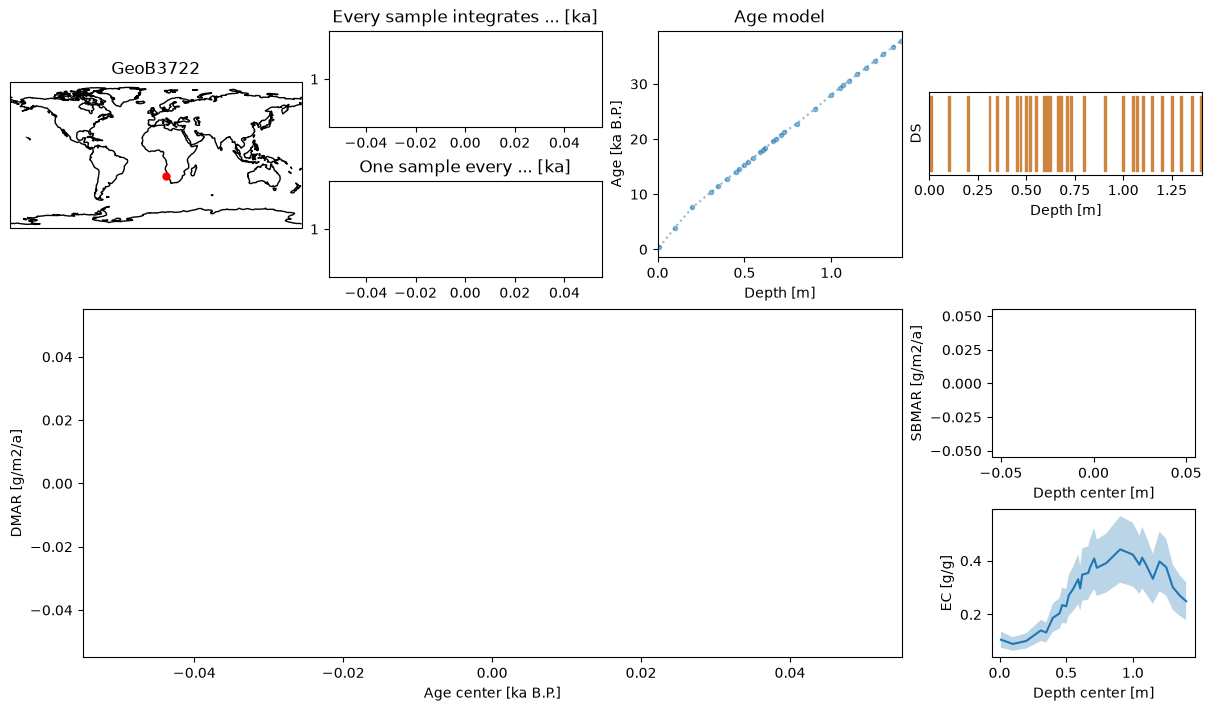

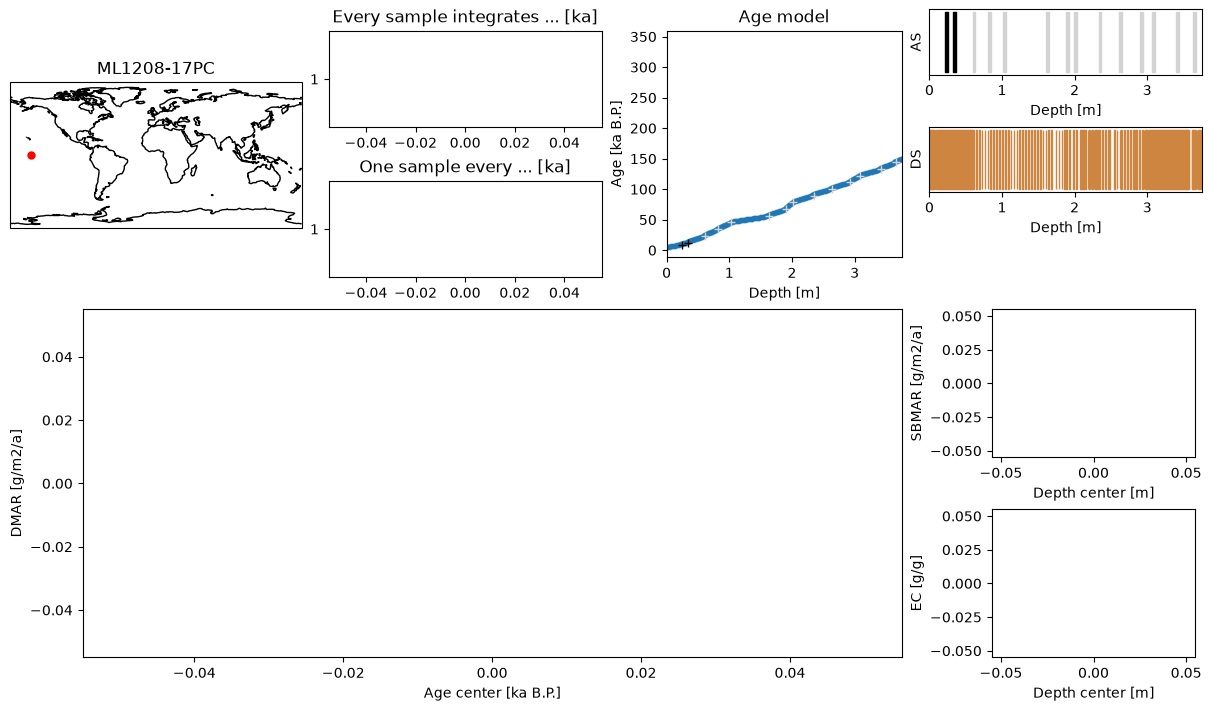

In [10]:
# Read the table with the list of sites and information on the the path to follow for processing

sites = pd.read_csv('sites_table.txt',sep='\t')
print(sites)
ns=len(sites.index)

# Process each site in the list, by performing the following operations:
  # Read A-Samples   
  # Read D-Samples 
  # Assign names, depths to the new df "calculations" 
  # Read age_model
  # Interpolate depths of D-Samples to the corresponding ages
  # Add ages, age uncertainties of D-Samples to the df "calculations" 
  # According to the specific template, complete "calculations" with SBMAR, EC, DMAR, and relative uncertainties
  # Evaluate size range ...
  # Copy key information to the main table
  # Print the tables to excel
  # Print the main table to text
  # Print pdf with record description and metadata


for nsi in tqdm(range(0,ns)):

  print('******',sites["Site"][nsi])    
  curn = './data_tables/'+sites["Site"][nsi]+'/'+ sites["Site"][nsi]
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')   

    
#-# Read Site_info (to keep input more readable, need to go through a few passages to transpose table)

  with open(curn+'_info_table.txt') as f:
   info00 = [[x for x in ln.split(sep='\t')] for ln in f]

  info01 = more_itertools.unzip(info00) # a tuple of generators.
  info01 = list(map(list, info01))      # a list of lists

  info = pd.DataFrame(info01)
  info.rename(columns=info.iloc[0], inplace = True)
  info=info.tail(-1)
  info.replace('\n','', regex=True,inplace=True)  

  print(info)
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')   

    
#-# Read A-Samples
    
  try:
    AS_table = pd.read_csv(curn+'_AS_table.txt',sep='\t')
    AS_flag=0
    print(AS_table.head())
    
  except:  
    print('A-Samples not available')
    AS_flag=1

    
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')     
    

    
#-# Read X-Samples
    
  try:
    XS_table = pd.read_csv(curn+'_XS_table.txt',sep='\t')
    XS_flag=0
    print(XS_table.head())

  except:  
    print('X-Samples not available')
    XS_flag=1

    
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~')     
    
    
#-# Read D-Samples  
    
  DS_table = pd.read_csv(curn+'_DS_table.txt',sep='\t')
  print(DS_table.head())  
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~') 


#-# Read age_model

  Age_table = pd.read_csv(curn+'_Age_model_table.txt',sep='\t')
  print(Age_table.head())  
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~') 


#-# Assign names, depths to the new df "calculations", and create columns for ages 

  calc_table = pd.DataFrame(DS_table.iloc[:,:4])
  calc_table[Atop]=np.nan
  calc_table[AtopRE]=np.nan
  calc_table[Abot]=np.nan
  calc_table[AbotRE]=np.nan
  calc_table[Ac]=np.nan
  calc_table[AcRE]=np.nan
  #print(calc_table.head())
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~') 


#-# Interpolate depths of D-Samples to the corresponding ages (top, bottom, center) and propagate uncertainties
  # Add to the "calculations" df

  for di in range(0,len(DS_table.index)):

    # (1) Depth (center)    
    
    # identify indices of age model depth that comprise the current D-Sample depth
    dd = abs(Age_table['Depth [m]']-DS_table[Dc][di])
    closest_1 = np.unravel_index(dd.argmin(), dd.shape)[0]
    dd[dd.argmin()]=np.nan
    closest_2 = np.unravel_index(dd.argmin(), dd.shape)[0]
    closest_pair=[closest_1,closest_2]

#    # If the values coincide, just take it - and its uncertainty;
#    if (DS_table[Dc][di] == Age_table['Depth [m]'][closest_1]): #[np.min(closest_pair)]):
#      calc_table[Ac][di] = Age_table['Age [ka B.P.]'][closest_1]
#      calc_table[AcRE][di] = Age_table['Age R.E. [frac., 2σ]'][closest_1]
    if (0==1):
      print('mmmm')  
    # Otherwise make linear interpolation, and propagate uncertainties  
    else:
      fuc = interpolate.interp1d([Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
                                 [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]],
                                 fill_value="extrapolate")
      calc_table[Ac][di] = fuc(calc_table[Dc][di])

      #calc_table[Ac][di] = np.interp(calc_table[Dc][di],
      #                                 [Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
      #                                 [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]])

      # Propagate the uncertainties
      calc_table[AcRE][di] = np.sqrt(np.square(Age_table['Age R.E. [frac., 2σ]'][np.min(closest_pair)])+
                                     np.square(Age_table['Age R.E. [frac., 2σ]'][np.max(closest_pair)]))
    
    # (2) Depth (top)

    # identify indices of age model depth that comprise the current D-Sample depth
    dd = abs(Age_table['Depth [m]']-DS_table[Dtop][di])
    closest_1 = np.unravel_index(dd.argmin(), dd.shape)[0]
    dd[dd.argmin()]=np.nan
    closest_2 = np.unravel_index(dd.argmin(), dd.shape)[0]
    closest_pair=[closest_1,closest_2]


    # Make the interpolation
    fut = interpolate.interp1d([Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
                               [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]],
                               fill_value="extrapolate")
    calc_table[Atop][di] = fut(calc_table[Dtop][di])
    #calc_table[Atop][di] = np.interp(calc_table[Dtop][di],
    #                           [Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
    #                           [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]])
    #print("@@",closest_pair,'\n',*Age_table['Depth [m]'][closest_pair],'\n',*Age_table['Age [ka B.P.]'][closest_pair],'\n',calc_table[Dtop][di],calc_table[Atop][di])
    
    # Propagate the uncertainties
    calc_table[AtopRE][di] = np.sqrt(np.square(Age_table['Age R.E. [frac., 2σ]'][np.min(closest_pair)])+
                                     np.square(Age_table['Age R.E. [frac., 2σ]'][np.max(closest_pair)]))
    
    
#    # If the top depth is zero, set the age to zero
#    if (calc_table[Dtop][di]==0):
#      calc_table[Atop][di] = 0.0
    
    # (3) Depth (bottom)    

    dd = abs(Age_table['Depth [m]']-DS_table[Dbot][di])
    closest_1 = np.unravel_index(dd.argmin(), dd.shape)[0]
    dd[dd.argmin()]=np.nan
    closest_2 = np.unravel_index(dd.argmin(), dd.shape)[0]
    closest_pair=[closest_1,closest_2]

    fub = interpolate.interp1d([Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
                               [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]],
                               fill_value="extrapolate")
    calc_table[Abot][di] = fub(calc_table[Dbot][di])
    
    
#    calc_table[Abot][di] = np.interp(calc_table[Dbot][di],
#                               [Age_table['Depth [m]'][np.min(closest_pair)],Age_table['Depth [m]'][np.max(closest_pair)]],
#                               [Age_table['Age [ka B.P.]'][np.min(closest_pair)],Age_table['Age [ka B.P.]'][np.max(closest_pair)]])

    # Propagate the uncertainties
    calc_table[AbotRE][di] = np.sqrt(np.square(Age_table['Age R.E. [frac., 2σ]'][np.min(closest_pair)])+
                                     np.square(Age_table['Age R.E. [frac., 2σ]'][np.max(closest_pair)]))
       
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~') 
    

#-# According to the specific template, complete "calculations" with SBMAR, EC, DMAR, and relative uncertainties

  # (Here I could define specific classes, alternatively)

  # MARINE SEDIMENTS (Type 1)
    
  if (sites['Type'][nsi]==1):  

    # Replicate DS columns
    calc_table[Th230] = DS_table[Th230]
    calc_table[Th230re] = DS_table[Th230re]    
    calc_table[Th232] = DS_table[Th232]
    calc_table[Th232re] = DS_table[Th232re]    
    calc_table[U234] = DS_table[U234]
    calc_table[U234re] = DS_table[U234re]    
    calc_table[U238] = DS_table[U238]
    calc_table[U238re] = DS_table[U238re]    
   
    # Create & populate new columns
    calc_table[Th230lith] = calc_table[Th232] * float(info['Lith. Corr.'].iloc[0])  # Costa20_eq3
    calc_table[Th230lithRE] = np.sqrt(np.square(calc_table[Th232re])+
                                      np.square(float(info['Lith. Corr. Abs. Err.'].iloc[0])/float(info['Lith. Corr.'].iloc[0])))   
    calc_table[U238auth] = calc_table[U238] - calc_table[Th230lith]  # Costa20_eq4
    calc_table[U238authRE] = np.sqrt(np.square(calc_table[U238re])+
                                     np.square(calc_table[Th230lithRE]))   
    calc_table[Th230auth] = calc_table[U238auth] * (1.-np.exp(-marine_lambda230*calc_table[Ac]))  # Costa20_eq5a
    calc_table[Th230authRE] = np.sqrt(np.square(calc_table[U238authRE])+
                                      np.square(marine_lambda230_RE)+
                                      np.square(calc_table[AcRE]))       
    calc_table[Th230xs] = calc_table[Th230]-calc_table[Th230auth]-calc_table[Th230lith]  # Costa20_eq2
    calc_table[Th230xsRE] = np.sqrt(np.square(calc_table[Th230re])+
                                    np.square(calc_table[Th230authRE])+
                                    np.square(calc_table[Th230lithRE]))       
    calc_table[Th230xs0] = calc_table[Th230xs] * np.exp(marine_lambda230*calc_table[Ac])    # Costa20_eq6
    calc_table[Th230xs0RE] = np.sqrt(np.square(calc_table[Th230xsRE])+
                                     np.square(marine_lambda230_RE)+
                                     np.square(calc_table[AcRE]))       
    calc_table[SBMAR] = -1*float(info['Elevation [m]'].iloc[0]) * marine_beta230 / calc_table[Th230xs0] # Costa20_eq7
    calc_table[SBMARRE] = np.sqrt(np.square(calc_table[Th230xs0RE])+
                                  np.square(marine_beta230_RE))       
    calc_table[Th232mr] = calc_table[Th232] / ATh230tomass      #
    calc_table[Th232mrRE] = np.sqrt(np.square(calc_table[Th232re])+
                                    np.square(ATh230tomass_RE))       
    calc_table[EC] = calc_table[Th232mr] / Th232todust      #
    calc_table[ECRE] = np.sqrt(np.square(calc_table[Th232mrRE])+
                               np.square(Th232todust_RE))           
    calc_table[DMAR] = calc_table[EC] * calc_table[SBMAR]
    calc_table[DMARRE] = np.sqrt(np.square(calc_table[ECRE])+
                                 np.square(calc_table[SBMARRE]))           
    
    
    
        
  print('~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~') 
    
    
    
#-# ...

  print(calc_table.head())
  calc_table.to_csv('./data_syntheses/'+sites["Site"][nsi]+'_calc_table.csv')



#-# Make summary plot

  #- Set multipanel plot

  fig = plt.figure(figsize=(12,7),constrained_layout=True)

  gs0 = fig.add_gridspec(nrows=2,ncols=2,height_ratios=[1.5,2], width_ratios=[3,1])

  gs00 = gs0[0,0].subgridspec(nrows=1, ncols=3) # map ; text/titles for A/D/X samples 
  gs000 = gs00[0,0].subgridspec(nrows=1, ncols=1) # map
  gs001 = gs00[0,1].subgridspec(nrows=2, ncols=1) # resolution statistics (boxplots)
  gs002 = gs00[0,2].subgridspec(nrows=1, ncols=1) # text/titles for A/D/X samples

  gs01 = gs0[0,1].subgridspec(nrows=3, ncols=1) # depth profiles of A/D/X samples
  gs11 = gs0[1,1].subgridspec(nrows=2, ncols=1) # profile of EC and SBMAR
  gs10 = gs0[1,0].subgridspec(nrows=1, ncols=1) # Time series of DMAR

  # Add map and title  
  
  smap = fig.add_subplot(gs000[0, 0],projection=crs.PlateCarree())
  smap.set_title(sites["Site"][nsi])
  smap.coastlines()
  smap.set_global()
  #smap.add_feature(cfeature.LAND)
  #smap.add_feature(cfeature.OCEAN)
  #ocean_10m = cfeature.NaturalEarthFeature('physical', 'ocean', '10m',
  #                                      edgecolor='face', facecolor=cfeature.COLORS['water'])
  #smap.add_feature(ocean_10m)
  smap.plot(sites["Longitude E"][nsi],sites["Latitide N"][nsi],
           color='red', marker='o', markersize=5)
  
  # Add time resolution & span statistics
    
  pstat1 = fig.add_subplot(gs001[0, 0])
  pstat1.set_title('Every sample integrates ... [ka]')
  pstat1.boxplot(calc_table[Abot]-calc_table[Atop],vert=False)
 
  pstat2 = fig.add_subplot(gs001[1, 0])
  pstat2.set_title('One sample every ... [ka]')
  pstat2.boxplot(calc_table[Ac].diff().dropna(),vert=False)

      
  # Add depth profiles of A/D/X samples 
# This could be one plot for all, with "If" to check what's available

  # DS first

  pDS = fig.add_subplot(gs01[1, 0]) 
  # also check: axs[0, 0].eventplot(
  slices = [Rectangle((top, 0), bot-top, 1) for top,bot in zip(calc_table[Dtop],calc_table[Dbot])]
  pc = PatchCollection(slices,edgecolor=None,color='peru')
  pDS.add_collection(pc)
  pDS.set_ylabel('DS')
  pDS.set_yticks([])
  pDS.set_xlabel('Depth [m]')
  core_depth = calc_table[Dbot].max()
  pDS.set_xlim(0,core_depth)
  pDS.use_sticky_edges = False  # has no effect apperently
  #pDS.plot(calc_table[Dc],[0.5]*len(calc_table[Dc]),linestyle='None')   # to make sure axis is constant


  # AS

  if (AS_flag ==0):
    #tAS = fig.add_subplot(gs002[0, 0]) 
    pAS = fig.add_subplot(gs01[0, 0]) 
       
    slices = [Rectangle((top, 0), bot-top, 1, color=colbar_AS[ty],edgecolor=None) 
              for top,bot,ty in zip(AS_table[Dtop],AS_table[Dbot],AS_table['Type'])]
    pc = PatchCollection(slices, match_original=True)
    pAS.add_collection(pc)
    pAS.set_ylabel('AS')
    pAS.set_yticks([])
    pAS.set_xlabel('Depth [m]')
    pAS.set_xlim(0,core_depth)

# Age samples: not all age samples may be used for the age model: should we plot them all ??
# This is the case for absolute ages treated as outliers by fitting algorithms, 
#  but also happens with e.g. d18O, for which only a few samples are tagged and used as stratigraphic 
#  markers for wiggle-matching to a stack (SPECMAP, LR04, ...)

# ** The solution for now is to mark only the tie-points and absolute ages **
    
  
  # XS
    
  if (XS_flag ==0):   
    #tXS = fig.add_subplot(gs002[2, 0])
    pXS = fig.add_subplot(gs01[2, 0])  
    

    
  # Add age model 
  # (shohuld it be only the portion of interest ??)

  colbar_AS=['black','crimson','lightgray']
   
  pAM = fig.add_subplot(gs002[0, 0]) 
  pAM.set_xlim(0,core_depth)  # limit to portion of interest (i.e. existing dust data)
  pAM.set_title('Age model')
  pAM.set_ylabel('Age [ka B.P.]')
  pAM.set_xlabel('Depth [m]') 
  pAM.plot(Age_table['Depth [m]'],Age_table['Age [ka B.P.]'],marker='.',linestyle=':',alpha=0.5)   
  if (AS_flag ==0):
    for nai in range(0,len(AS_table[Dc])):
      pAM.plot(AS_table[Dc][nai],AS_table['Age [ka B.P.]'][nai],colbar_AS[AS_table['Type'][nai]],marker='+')      

  
  # Add profile of EC and SBMAR

  pSBMAR = fig.add_subplot(gs11[0, 0]) 
  pSBMAR.set_xlabel(Dc)
  pSBMAR.set_ylabel(SBMAR)
  pSBMAR.fill_between(calc_table[Dc], calc_table[SBMAR]-calc_table[SBMAR]*calc_table[SBMARRE], 
                      calc_table[SBMAR]+calc_table[SBMAR]*calc_table[SBMARRE],alpha=0.3)
  pSBMAR.plot(calc_table[Dc],calc_table[SBMAR])
    
  pEC = fig.add_subplot(gs11[1, 0]) 
  pEC.set_xlabel(Dc)
  pEC.set_ylabel(EC)
  pEC.fill_between(calc_table[Dc], calc_table[EC]-calc_table[EC]*calc_table[ECRE], 
                      calc_table[EC]+calc_table[EC]*calc_table[ECRE],alpha=0.3)
  pEC.plot(calc_table[Dc],calc_table[EC])

  # Add time series of DMAR vs Age

  pDMAR = fig.add_subplot(gs10[0, 0])  
    
  # Simulate data from a bivariate Gaussian
#  n = 10000
#  for si in range(0,len(calc_table[Ac])):
#    bvg_mean = [calc_table[Ac][si], calc_table[DMAR][si]]  ;print(bvg_mean)
#    cov = [(calc_table[AcRE][si], calc_table[DMARRE][si]), (calc_table[DMARRE][si], calc_table[AcRE][si])]
#    rng = np.random.RandomState(0)
#    x, y = rng.multivariate_normal(bvg_mean[si], cov[si], n).T
    #sns.kdeplot(x=x, y=y, levels=5, color="w", linewidths=1)
    
    
  pDMAR.set_xlabel(Ac)
  pDMAR.set_ylabel(DMAR)
    
  pDMAR.plot(calc_table[Ac]-0.5*calc_table[Ac]*calc_table[AcRE],calc_table[DMAR],color='tan',alpha=0.5,linestyle=':')  
  pDMAR.plot(calc_table[Ac]+0.5*calc_table[Ac]*calc_table[AcRE],calc_table[DMAR],color='tan',alpha=0.5,linestyle=':')  
  pDMAR.plot(calc_table[Ac]-1*calc_table[Ac]*calc_table[AcRE],calc_table[DMAR],color='tan',alpha=0.2,linestyle=':')  
  pDMAR.plot(calc_table[Ac]+1*calc_table[Ac]*calc_table[AcRE],calc_table[DMAR],color='tan',alpha=0.2,linestyle=':')  
    
#  pDMAR.fill_between(calc_table[Ac], calc_table[DMAR]-calc_table[DMAR]*calc_table[DMARRE], 
#                     calc_table[DMAR]+calc_table[DMAR]*calc_table[DMARRE],alpha=0.3)
#  pDMAR.fill_betweenx(calc_table[DMAR], calc_table[Ac]-calc_table[Ac]*calc_table[AcRE], 
#                      calc_table[Ac]+calc_table[Ac]*calc_table[AcRE],alpha=0.3,color='yellow')#,interpolate=True )

#  pDMAR.plot([calc_table[Ac]-calc_table[Ac]*calc_table[AcRE],calc_table[Ac]+calc_table[Ac]*calc_table[AcRE]],
#             [calc_table[DMAR],calc_table[DMAR]],color='gold',linewidth=0.1)
#  pDMAR.plot([calc_table[Ac],calc_table[Ac]],
#             [calc_table[DMAR]-calc_table[DMAR]*calc_table[DMARRE], 
#              calc_table[DMAR]+calc_table[DMAR]*calc_table[DMARRE]],color='grey',linewidth=0.1)

#  pDMAR.plot(calc_table[Ac],calc_table[DMAR],linestyle="None",markersize=5,marker="+",color='r')

    
  slices1 = [Rectangle((Atop,Dmin),Abot-Atop,Dmax-Dmin)
             for Atop,Abot,Dmin,Dmax in zip(calc_table[Atop],calc_table[Abot],
                                            calc_table[DMAR]-calc_table[DMARRE]*calc_table[DMAR],
                                            calc_table[DMAR]+calc_table[DMARRE]*calc_table[DMAR])]
  slices2 = [Rectangle((Atop,Dmin),Abot-Atop,Dmax-Dmin)
             for Atop,Abot,Dmin,Dmax in zip(calc_table[Atop],calc_table[Abot],
                                            calc_table[DMAR]-0.5*calc_table[DMARRE]*calc_table[DMAR],
                                            calc_table[DMAR]+0.5*calc_table[DMARRE]*calc_table[DMAR])]

  pc1 = PatchCollection(slices1,color='peru',alpha=0.2,edgecolor=None)
  pc2 = PatchCollection(slices2,color='peru',alpha=0.5,edgecolor=None)
  pDMAR.add_collection(pc1) ; pDMAR.add_collection(pc2)

#twilight bw should be good for 1D SD i.e. for DMAR
    
# https://stackoverflow.com/questions/10958835/matplotlib-color-gradient-in-patches    
# https://stackoverflow.com/questions/66837477/how-to-gradient-fill-drawn-shapes

  pDMAR.plot(calc_table[Ac],calc_table[DMAR],color='peru',linestyle=':')
  pDMAR.plot([calc_table[Abot],calc_table[Atop]],[calc_table[DMAR],calc_table[DMAR]],color='r')


  # Further improvemenets:
  # - confidence level
  # - boxplot with age uncertainty?
  # - test case with A-Samples info
  # - test case with Size-Samples
  # - consider case for multiple X-Samples (e.g. elemental, mineralogical, isotopical composition)



  #fig.tight_layout()
  #plt.show()
  plt.savefig('./data_syntheses/'+sites["Site"][nsi]+'_summary.pdf')  


    
  # Also, needs to print an info page for each record, including the text information

  # https://tex.stackexchange.com/questions/885/how-can-i-use-latex-from-python 

    

In [6]:
# Write into json (geo-json) format
# and/or L

In [7]:
# Notes


# I could add a zoomed-in google earth map showing the context (blue-marble, ocean bathymetry) of the site 
#  in a e.g. 3x3 deg. window

# https://developers.google.com/earth-engine/tutorials/community/intro-to-python-api-guiattard#get_a_static_map
# https://www.kaggle.com/carlmcbrideellis/bluemarble-and-etopo-in-cartopy?select=etopo.png
# https://scitools.org.uk/cartopy/docs/latest/gallery/web_services/image_tiles.html#sphx-glr-gallery-web-services-image-tiles-py

# adding cfeatures is not workin, and the pdf also looks empty
